# Preprocessing Data Terpadu: Ketahanan Pangan & Kelaparan 2024
### Notebook 05: Penyiapan Master Dataset untuk ANOVA, K-Means Clustering, & Regresi Linear Berganda
**Mata Kuliah**: Presentasi dan Storytelling Data  
**Dataset Utama**:
1. **Indeks Ketahanan Pangan (IKP) 2024** - Badan Pangan Nasional (Bapanas)
2. **Prevalensi Ketidakcukupan Konsumsi Pangan (PoU) 2024** - Badan Pusat Statistik (BPS)

---
### 7 Langkah Preprocessing yang Dilakukan:
1. **Load Data & Filter Tahun**: Memilih basis cross-sectional tahun 2024 ($N=514$ kabupaten/kota).
2. **Harmonisasi Ejaan Wilayah**: Menyelaraskan 21 anomali nama daerah antara Bapanas dan BPS (misal pembaruan nomenklatur PP: Toba, Tanimbar, Pasangkayu).
3. **Penyatuan Dataset (1:1 Inner Join)**: Menggabungkan data komposit IKP, 3 pilar, dan PoU dengan verifikasi kecocokan 100%.
4. **Rekayasa Fitur Geografis**:
   - Pemetaan 38 provinsi ke dalam **7 Gugus Kepulauan**.
   - Ekstraksi klasifikasi administratif (**Kabupaten vs Kota**).
5. **Validasi Kualitas Data (*Sanity Check*)**: Memastikan tidak ada missing value, outlier ekstrim, atau ketidaksesuaian skala (0-100).
6. **Penskalaan Multivariat (*Feature Scaling*)**: Membuat kolom Z-score terstandarisasi untuk K-Means dan regresi.
7. **Ekspor Master Dataset**: Menyimpan dataset terintegrasi ke `data/processed/master_analisis_2024.csv`.


## 1. Import Library & Setup Lingkungan


In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Konfigurasi visualisasi
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Direktori proyek
RAW_DIR = os.path.join('..', 'data', 'raw') if os.path.exists(os.path.join('..', 'data', 'raw')) else os.path.join('data', 'raw')
PROCESSED_DIR = os.path.join('..', 'data', 'processed') if os.path.exists(os.path.join('..', 'data', 'processed')) else os.path.join('data', 'processed')
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Direktori raw      :", RAW_DIR)
print("Direktori processed:", PROCESSED_DIR)


Direktori raw      : ..\data\raw
Direktori processed: ..\data\processed


## 2. Load Dataset Mentah (IKP & PoU 2024)


In [2]:
# 1. Load IKP 2024-2026
ikp_path = os.path.join(RAW_DIR, 'dataset_ikp', 'IKP 2024-2026.csv')
df_ikp_raw = pd.read_csv(ikp_path)
df_ikp_raw.columns = df_ikp_raw.columns.str.strip()

# Filter tahun acuan 2024
df_ikp = df_ikp_raw[df_ikp_raw['Tahun'] == 2024].copy()
print(f"Dataset IKP 2024: {len(df_ikp)} kabupaten/kota")

# 2. Load PoU 2024
pou_path = os.path.join(RAW_DIR, 'dataset_pou', 'Prevalensi Ketidakcukupan Konsumsi Pangan (Persen) Per Kabupaten_kota, 2024.csv')
df_pou = pd.read_csv(pou_path, skiprows=3, names=['kabupaten_kota', 'pou'], encoding='utf-8')
df_pou['kabupaten_kota'] = df_pou['kabupaten_kota'].str.strip()
df_pou['pou'] = pd.to_numeric(df_pou['pou'], errors='coerce')
print(f"Dataset PoU 2024: {len(df_pou)} kabupaten/kota")


Dataset IKP 2024: 514 kabupaten/kota
Dataset PoU 2024: 514 kabupaten/kota


## 3. Harmonisasi Nomenklatur Wilayah (BPS vs Bapanas)
BPS dan Bapanas memiliki sedikit perbedaan ejaan nama daerah (misal pemisahan spasi, penghapusan kata 'kabupaten', dan pembaruan nama daerah sesuai Peraturan Pemerintah terbaru). Berikut kamus pemetaan 21 daerah khusus agar penggabungan presisi 100%.


In [3]:
# Kamus koreksi nama daerah PoU (BPS) agar sesuai dengan standar IKP (Bapanas)
pou_to_ikp_mapping = {
    'banyu asin': 'banyuasin',
    'batang hari': 'batanghari',
    'fakfak': 'fak fak',
    'gunung kidul': 'gunungkidul',
    'kepulauan seribu': 'kep. seribu',
    'siau tagulandang biaro': 'kep. siau tagulandang biaro',
    'maluku tenggara barat': 'kepulauan tanimbar',    # PP No. 2 Tahun 2019
    'kota banjar baru': 'kota banjarbaru',
    'kota baru': 'kotabaru',
    'kota baubau': 'kota bau-bau',
    'kota lubuklinggau': 'kota lubuk linggau',
    'kota palangka raya': 'kota palangkaraya',
    'kota pematang siantar': 'kota pematangsiantar',
    'kota sawah lunto': 'kota sawahlunto',
    'labuhan batu': 'labuhanbatu',
    'labuhan batu selatan': 'labuhanbatu selatan',
    'labuhan batu utara': 'labuhanbatu utara',
    'mamuju utara': 'pasangkayu',                    # PP No. 61 Tahun 2017
    'toba samosir': 'toba',                          # PP No. 14 Tahun 2020
    'tojo una-una': 'tojo una una',
    'tulangbawang': 'tulang bawang'
}

df_pou['kab_clean'] = df_pou['kabupaten_kota'].str.strip().str.lower().replace(pou_to_ikp_mapping)
df_ikp['kab_clean'] = df_ikp['Nama Kabupaten'].str.strip().str.lower()

diff = set(df_ikp['kab_clean']) ^ set(df_pou['kab_clean'])
print(f"Selisih nama daerah setelah harmonisasi: {len(diff)} (0 = 100% cocok sempurna)")


Selisih nama daerah setelah harmonisasi: 0 (0 = 100% cocok sempurna)


## 4. Penggabungan Data (1:1 Inner Join)


In [4]:
# Lakukan merge
df_merged = pd.merge(
    df_ikp,
    df_pou[['kab_clean', 'pou']],
    on='kab_clean',
    how='inner'
)

print(f"Total baris hasil penggabungan: {len(df_merged)} dari 514 wilayah nasional")
assert len(df_merged) == 514, "Gagal: jumlah baris tidak tepat 514!"


Total baris hasil penggabungan: 514 dari 514 wilayah nasional


## 5. Rekayasa Fitur Geografis & Administratif
Memetakan 38 Provinsi ke dalam **7 Gugus Kepulauan Utama** dan mengelompokkan **Tipe Daerah (Kabupaten vs Kota)**.


In [5]:
# Mapping 38 Provinsi ke 7 Gugus Kepulauan
gugus_map = {
    'Aceh': 'Sumatera', 'Sumatera Utara': 'Sumatera', 'Sumatera Barat': 'Sumatera',
    'Riau': 'Sumatera', 'Jambi': 'Sumatera', 'Sumatera Selatan': 'Sumatera',
    'Bengkulu': 'Sumatera', 'Lampung': 'Sumatera', 'Kep. Bangka Belitung': 'Sumatera',
    'Kep. Riau': 'Sumatera', 'DKI Jakarta': 'Jawa', 'Jawa Barat': 'Jawa',
    'Jawa Tengah': 'Jawa', 'DI Yogyakarta': 'Jawa', 'Jawa Timur': 'Jawa',
    'Banten': 'Jawa', 'Bali': 'Bali-Nusa Tenggara', 'Nusa Tenggara Barat': 'Bali-Nusa Tenggara',
    'Nusa Tenggara Timur': 'Bali-Nusa Tenggara', 'Kalimantan Barat': 'Kalimantan',
    'Kalimantan Tengah': 'Kalimantan', 'Kalimantan Selatan': 'Kalimantan',
    'Kalimantan Timur': 'Kalimantan', 'Kalimantan Utara': 'Kalimantan',
    'Sulawesi Utara': 'Sulawesi', 'Sulawesi Tengah': 'Sulawesi',
    'Sulawesi Selatan': 'Sulawesi', 'Sulawesi Tenggara': 'Sulawesi',
    'Gorontalo': 'Sulawesi', 'Sulawesi Barat': 'Sulawesi',
    'Maluku': 'Maluku', 'Maluku Utara': 'Maluku',
    'Papua': 'Papua', 'Papua Barat': 'Papua', 'Papua Selatan': 'Papua',
    'Papua Tengah': 'Papua', 'Papua Pegunungan': 'Papua', 'Papua Barat Daya': 'Papua'
}

# Standarisasi kolom utama
master_df = pd.DataFrame({
    'kode_prov': df_merged['Kode Prov'],
    'nama_provinsi': df_merged['Nama Provinsi'].str.strip(),
    'kode_kab_kota': df_merged['Kode Kab/Kota'],
    'nama_kabupaten': df_merged['Nama Kabupaten'].str.strip(),
    'tipe': df_merged['Nama Kabupaten'].apply(lambda x: 'Kota' if 'kota' in str(x).lower() else 'Kabupaten'),
    'gugus_pulau': df_merged['Nama Provinsi'].str.strip().map(gugus_map),
    'ikp': df_merged['IKP'].round(2),
    'indeks_ketersediaan': df_merged['Indeks Ketersediaan'].round(2),
    'indeks_keterjangkauan': df_merged['Indeks Keterjangkauan'].round(2),
    'indeks_pemanfaatan': df_merged['Indeks Pemanfaatan'].round(2),
    'status_kerentanan': df_merged['Status Kerentanan'].str.strip(),
    'pou': df_merged['pou'].round(2)
})

# Distribusi wilayah per gugus dan tipe
print("Distribusi Wilayah per Gugus dan Tipe:")
display(pd.crosstab(master_df['gugus_pulau'], master_df['tipe'], margins=True))


Distribusi Wilayah per Gugus dan Tipe:


tipe,Kabupaten,Kota,All
gugus_pulau,,,
Bali-Nusa Tenggara,37,4,41
Jawa,85,34,119
Kalimantan,44,12,56
Maluku,17,4,21
Papua,40,2,42
Sulawesi,70,11,81
Sumatera,119,35,154
All,412,102,514


## 6. Validasi Kualitas Data (*Sanity Check*)


In [6]:
print("--- RINGKASAN VALIDASI KUALITAS DATA ---")
print("Missing Values per Kolom:")
print(master_df.isnull().sum())

print("\nStatistik Deskriptif Variabel Utama:")
display(master_df[['ikp', 'indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan', 'pou']].describe().round(2))

# Validasi rentang logis
assert master_df['ikp'].between(0, 100).all(), "Skor IKP di luar rentang 0-100!"
assert master_df['indeks_ketersediaan'].between(0, 100).all(), "Skor Ketersediaan di luar rentang 0-100!"
assert master_df['indeks_keterjangkauan'].between(0, 100).all(), "Skor Keterjangkauan di luar rentang 0-100!"
assert master_df['indeks_pemanfaatan'].between(0, 100).all(), "Skor Pemanfaatan di luar rentang 0-100!"
assert master_df['pou'].between(0, 100).all(), "Skor PoU di luar rentang 0-100%!"
print("\nSemua nilai numerik valid dan berada dalam batas teoretis yang sah.")


--- RINGKASAN VALIDASI KUALITAS DATA ---
Missing Values per Kolom:
kode_prov                0
nama_provinsi            0
kode_kab_kota            0
nama_kabupaten           0
tipe                     0
gugus_pulau              0
ikp                      0
indeks_ketersediaan      0
indeks_keterjangkauan    0
indeks_pemanfaatan       0
status_kerentanan        0
pou                      0
dtype: int64

Statistik Deskriptif Variabel Utama:


,ikp,indeks_ketersediaan,indeks_keterjangkauan,indeks_pemanfaatan,pou
count,514.00,514.00,514.00,514.00,514.00
mean,68.04,57.09,78.18,69.02,11.08
std,10.01,15.60,8.45,12.60,8.73
min,30.05,9.39,43.34,17.34,0.87
25%,64.67,49.82,75.03,61.45,6.20
50%,70.46,58.24,79.77,71.07,8.69
75%,74.30,65.96,83.58,78.18,12.34
max,86.58,94.75,92.44,93.69,57.91



Semua nilai numerik valid dan berada dalam batas teoretis yang sah.


## 7. Penskalaan Multivariat untuk K-Means & Regresi
Menghitung skor Z-score ($\mu=0, \sigma=1$) untuk 3 pilar IKP dan PoU. Ini diperlukan agar jarak Euclidean pada K-Means tidak bias terhadap fitur dengan varians terbesar.


In [7]:
scaler = StandardScaler()
features_to_scale = ['indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan', 'pou']
scaled_matrix = scaler.fit_transform(master_df[features_to_scale])

for i, col in enumerate(features_to_scale):
    master_df[f'z_{col}'] = np.round(scaled_matrix[:, i], 4)

print("Kolom Z-Score berhasil ditambahkan:")
display(master_df[[f'z_{col}' for col in features_to_scale]].head())


Kolom Z-Score berhasil ditambahkan:


,z_indeks_ketersediaan,z_indeks_keterjangkauan,z_indeks_pemanfaatan,z_pou
0,1.2564,-0.2997,-0.8624,-0.0733
1,0.2896,-0.6420,-0.6615,-0.1880
2,0.0753,-0.1540,-0.0500,-0.2717
3,-0.4161,0.1184,0.3352,-0.2499
4,0.4788,-0.9074,0.1796,-0.3061


## 8. Matriks Korelasi Awal (Preview Hubungan Antar-Pilar & PoU)


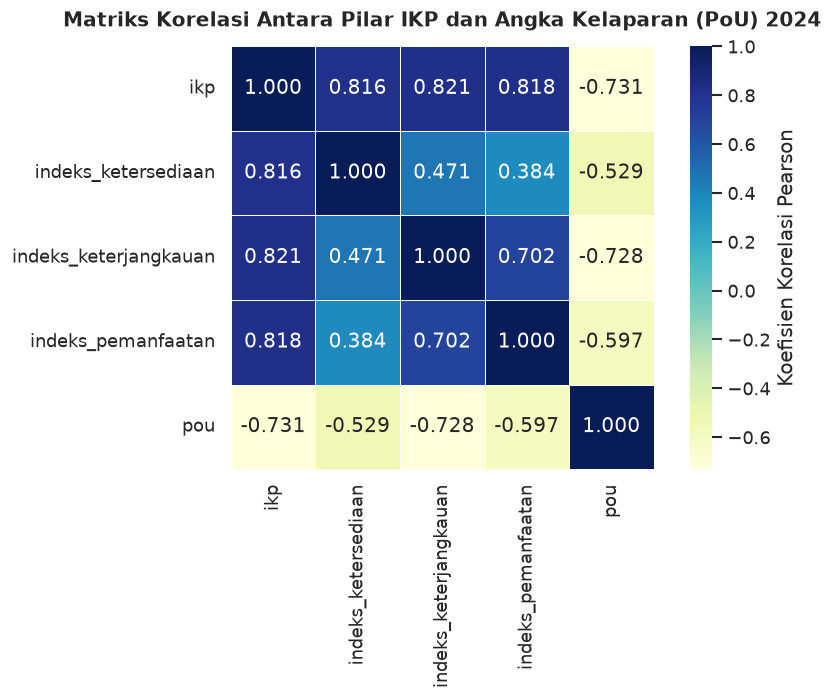

In [8]:
plt.figure(figsize=(8, 6))
corr_cols = ['ikp', 'indeks_ketersediaan', 'indeks_keterjangkauan', 'indeks_pemanfaatan', 'pou']
corr = master_df[corr_cols].corr()

sns.heatmap(corr, annot=True, cmap='YlGnBu', fmt='.3f', square=True, linewidths=0.5, cbar_kws={'label': 'Koefisien Korelasi Pearson'})
plt.title('Matriks Korelasi Antara Pilar IKP dan Angka Kelaparan (PoU) 2024', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 9. Ekspor Master Dataset Terintegrasi
File CSV ini akan menjadi **single source of truth** bagi:
1. Model 1: **ANOVA & Post-Hoc Tukey HSD**
2. Model 2: **K-Means Clustering Wilayah**
3. Model 3: **Multiple Linear Regression (Faktor Penentu PoU)**


In [9]:
output_csv = os.path.join(PROCESSED_DIR, 'master_analisis_2024.csv')
master_df.to_csv(output_csv, index=False)
print("Master dataset berhasil diekspor ke:", output_csv)
print(f"Dimensi akhir: {master_df.shape[0]} baris x {master_df.shape[1]} kolom")
print("Contoh 5 baris pertama:")
display(master_df.head())


Master dataset berhasil diekspor ke: ..\data\processed\master_analisis_2024.csv
Dimensi akhir: 514 baris x 16 kolom
Contoh 5 baris pertama:


,kode_prov,nama_provinsi,kode_kab_kota,nama_kabupaten,tipe,gugus_pulau,ikp,indeks_ketersediaan,indeks_keterjangkauan,indeks_pemanfaatan,status_kerentanan,pou,z_indeks_ketersediaan,z_indeks_keterjangkauan,z_indeks_pemanfaatan,z_pou
0,11,Aceh,1101,Aceh Selatan,Kabupaten,Sumatera,70.13,76.67,75.65,58.16,Tahan,10.44,1.2564,-0.2997,-0.8624,-0.0733
1,11,Aceh,1102,Aceh Tenggara,Kabupaten,Sumatera,64.98,61.60,72.76,60.69,Agak Tahan,9.44,0.2896,-0.6420,-0.6615,-0.1880
2,11,Aceh,1103,Aceh Timur,Kabupaten,Sumatera,67.80,58.26,76.88,68.39,Agak Tahan,8.71,0.0753,-0.1540,-0.0500,-0.2717
3,11,Aceh,1104,Aceh Tengah,Kabupaten,Sumatera,67.62,50.60,79.18,73.24,Agak Tahan,8.90,-0.4161,0.1184,0.3352,-0.2499
4,11,Aceh,1105,Aceh Barat,Kabupaten,Sumatera,68.78,64.55,70.52,71.28,Agak Tahan,8.41,0.4788,-0.9074,0.1796,-0.3061
